# TP Evaluativo Nº 1 — Proceso KDD completo: Regresión Lineal vs. Árbol de Decisión
**Minería de Datos II · ITSE · Tecnicatura Superior en Ciencia de Datos e IA**

**Dataset:** Wine Quality (Vinho Verde tinto) — UCI ML Repository (Cortez et al., 2009)
**Objetivo:** estimar el puntaje `quality` (variable continua) a partir de 11 variables fisicoquímicas, comparando una Regresión Lineal Múltiple y un `DecisionTreeRegressor`.


In [ ]:
# ============ Imports y configuración global ============
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42  # reproducibilidad
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


def metricas(y_true, y_pred):
    """Devuelve MAE, RMSE y R2."""
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

---
# ETAPA 1 — Selección de datos

**Decisión:** se usa el dataset *Wine Quality (tinto)* porque es el indicado en la consigna: 1.599 muestras, 11 predictores numéricos continuos y un target (`quality`) que podemos tratar como variable continua para un problema de regresión.

In [ ]:
# ---- 1. Descarga y carga en un DataFrame ----
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

try:
    df_raw = pd.read_csv(URL, sep=";")          # el CSV está separado por ';'
except Exception as e:
    # Respaldo: ZIP oficial de UCI (por si el enlace directo cambia)
    print("Falló el enlace directo, probando el ZIP oficial...", e)
    import io, zipfile, urllib.request
    ZIP = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"
    with urllib.request.urlopen(ZIP) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
    df_raw = pd.read_csv(z.open("winequality-red.csv"), sep=";")

df_raw.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5
1,7.8000,0.8800,0.0000,2.6000,0.0980,25.0000,67.0000,0.9968,3.2000,0.6800,9.8000,5
2,7.8000,0.7600,0.0400,2.3000,0.0920,15.0000,54.0000,0.9970,3.2600,0.6500,9.8000,5
3,11.2000,0.2800,0.5600,1.9000,0.0750,17.0000,60.0000,0.9980,3.1600,0.5800,9.8000,6
4,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5


In [ ]:
# ---- 2. Estructura del dataset y EDA descriptivo ----
print("Dimensiones:", df_raw.shape)
print("\nTipos de datos:")
print(df_raw.dtypes)
df_raw.describe().T

Dimensiones: (1599, 12)

Tipos de datos:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


,count,mean,std,min,25%,50%,75%,max
fixed acidity,"1,599.0000",8.3196,1.7411,4.6000,7.1000,7.9000,9.2000,15.9000
volatile acidity,"1,599.0000",0.5278,0.1791,0.1200,0.3900,0.5200,0.6400,1.5800
citric acid,"1,599.0000",0.2710,0.1948,0.0000,0.0900,0.2600,0.4200,1.0000
residual sugar,"1,599.0000",2.5388,1.4099,0.9000,1.9000,2.2000,2.6000,15.5000
chlorides,"1,599.0000",0.0875,0.0471,0.0120,0.0700,0.0790,0.0900,0.6110
free sulfur dioxide,"1,599.0000",15.8749,10.4602,1.0000,7.0000,14.0000,21.0000,72.0000
total sulfur dioxide,"1,599.0000",46.4678,32.8953,6.0000,22.0000,38.0000,62.0000,289.0000
density,"1,599.0000",0.9967,0.0019,0.9901,0.9956,0.9968,0.9978,1.0037
pH,"1,599.0000",3.3111,0.1544,2.7400,3.2100,3.3100,3.4000,4.0100
sulphates,"1,599.0000",0.6581,0.1695,0.3300,0.5500,0.6200,0.7300,2.0000


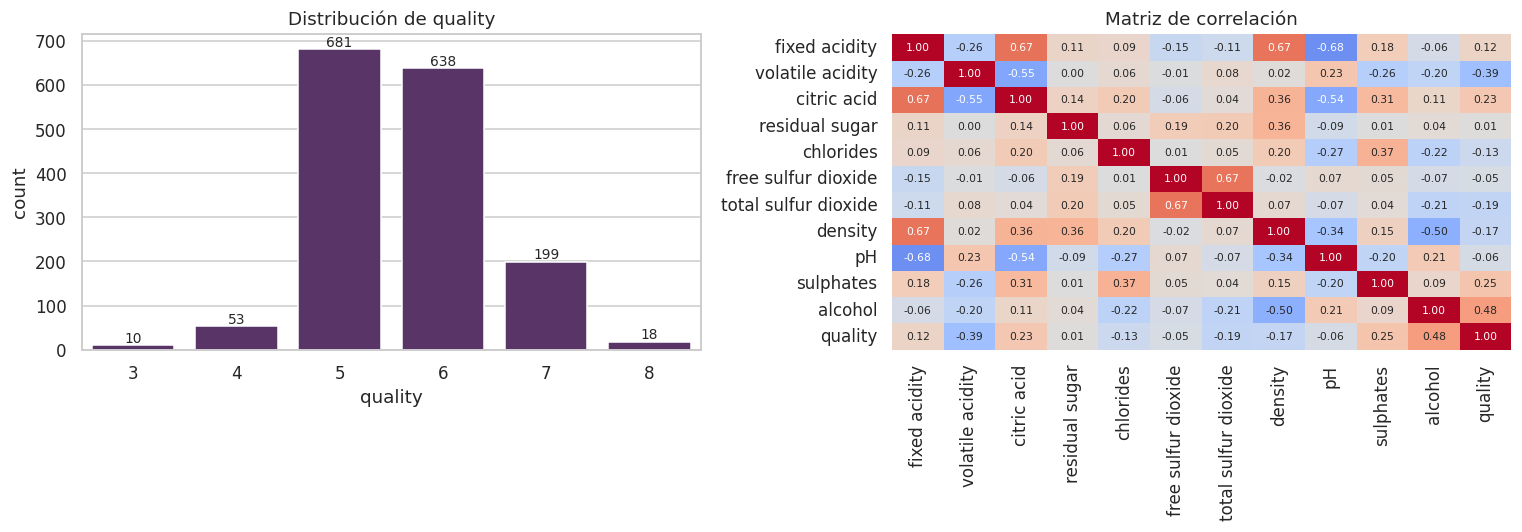

Correlación de cada variable con quality:
alcohol                 0.4762
sulphates               0.2514
citric acid             0.2264
fixed acidity           0.1241
residual sugar          0.0137
free sulfur dioxide    -0.0507
pH                     -0.0577
chlorides              -0.1289
density                -0.1749
total sulfur dioxide   -0.1851
volatile acidity       -0.3906
Name: quality, dtype: float64


In [ ]:
# Distribución del target y matriz de correlación
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x="quality", data=df_raw, ax=ax[0], color="#5b2c6f")
ax[0].set_title("Distribución de quality")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                   ha="center", va="bottom", fontsize=9)

sns.heatmap(df_raw.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            ax=ax[1], annot_kws={"size": 7}, cbar=False)
ax[1].set_title("Matriz de correlación")
plt.tight_layout(); plt.show()

print("Correlación de cada variable con quality:")
print(df_raw.corr()["quality"].drop("quality").sort_values(ascending=False))

**Lectura del EDA:**
- `quality` toma valores solo entre 3 y 8, concentrados en 5 y 6 (clases extremas muy poco representadas). Esto limita la capacidad de cualquier modelo de predecir los extremos y hace que las predicciones tiendan a "regresar" hacia el centro.
- Las variables con mayor correlación con `quality` son `alcohol` (positiva) y `volatile acidity` (negativa).
- Hay correlaciones fuertes entre predictores (p. ej. `fixed acidity` con `density`, `citric acid` y `pH`) → **multicolinealidad**, relevante para interpretar los coeficientes de la regresión lineal.
- Las escalas de las variables son muy distintas (p. ej. `total sulfur dioxide` vs. `chlorides`), lo que condiciona la interpretación de coeficientes (se retoma en la Etapa 3).

---
# ETAPA 2 — Preprocesamiento y limpieza

In [ ]:
# ---- 3. Estandarizar mayúsculas/minúsculas ----
df = df_raw.copy()
df.columns = (df.columns.str.strip().str.lower().str.replace(" ", "_", regex=False))

# Estandarizacion de columnas de texto
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip().str.lower()

print("Columnas estandarizadas:", list(df.columns))
print("Columnas de tipo texto:", list(df.select_dtypes(include='object').columns))

Columnas estandarizadas: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol', 'quality']
Columnas de tipo texto: []


**Decisión (punto 3):** todos los nombres de columnas pasan a minúsculas, sin espacios (`fixed acidity` → `fixed_acidity`). Esto evita errores de tipeo/acceso y mantiene un formato uniforme. El dataset no contiene variables categóricas de texto, por lo que no hay valores a unificar.

In [ ]:
# ---- 4. Valores nulos ----
nulos = df.isnull().sum()
print("Nulos por columna:\n", nulos)
print("\nTotal de nulos:", int(nulos.sum()))

# Chequeo adicional: ceros que podrían ser "nulos disfrazados"
print("\nCantidad de ceros por columna (solo informativo):")
print((df == 0).sum()[lambda s: s > 0])

Nulos por columna:
 fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
ph                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total de nulos: 0

Cantidad de ceros por columna (solo informativo):
citric_acid    132
dtype: int64


**Decisión (punto 4):** el dataset **no presenta valores nulos**, por lo que no se imputa ni se eliminan filas por este motivo. Los únicos ceros están en `citric_acid`, que es un valor fisicoquímicamente posible (vinos sin ácido cítrico agregado), no un dato faltante, por lo que se conservan.
*(Si hubiera habido nulos, la imputación —p. ej. mediana— debería ajustarse sólo con el conjunto de entrenamiento para no filtrar información del test.)*

In [ ]:
# ---- 5. Filas duplicadas exactas ----
n_dup = df.duplicated().sum()
print(f"Filas duplicadas exactas: {n_dup} ({n_dup/len(df):.1%} del total)")

df_con_dup = df.copy()
df = df.drop_duplicates().reset_index(drop=True)    # eliminamos ANTES de dividir train/test
print("Tamaño tras eliminar duplicados:", df.shape)

Filas duplicadas exactas: 240 (15.0% del total)
Tamaño tras eliminar duplicados: (1359, 12)


**Decisión (punto 5):** se **eliminan** las duplicadas exactas **antes** de dividir en entrenamiento y prueba. Si se dejaran, una misma observación podría quedar en ambos conjuntos (*data leakage*): el modelo la "vería" al entrenar y luego sería evaluada en prueba, inflando artificialmente las métricas —sobre todo en modelos que memorizan, como un árbol profundo—. Ver respuesta ampliada en la pregunta 20.

,Q1,Q3,lim_inf,lim_sup,n_outliers,% outliers
variable,,,,,,
residual_sugar,1.9000,2.6000,0.8500,3.6500,126,9.2715
chlorides,0.0700,0.0910,0.0385,0.1225,87,6.4018
sulphates,0.5500,0.7300,0.2800,1.0000,55,4.0471
total_sulfur_dioxide,22.0000,63.0000,-39.5000,124.5000,45,3.3113
fixed_acidity,7.1000,9.2000,3.9500,12.3500,41,3.0169
density,0.9956,0.9978,0.9923,1.0011,35,2.5754
ph,3.2100,3.4000,2.9250,3.6850,28,2.0603
free_sulfur_dioxide,7.0000,21.0000,-14.0000,42.0000,26,1.9132
volatile_acidity,0.3900,0.6400,0.0150,1.0150,19,1.3981



Filas con al menos un outlier en alguna variable: 340 (25.0%)


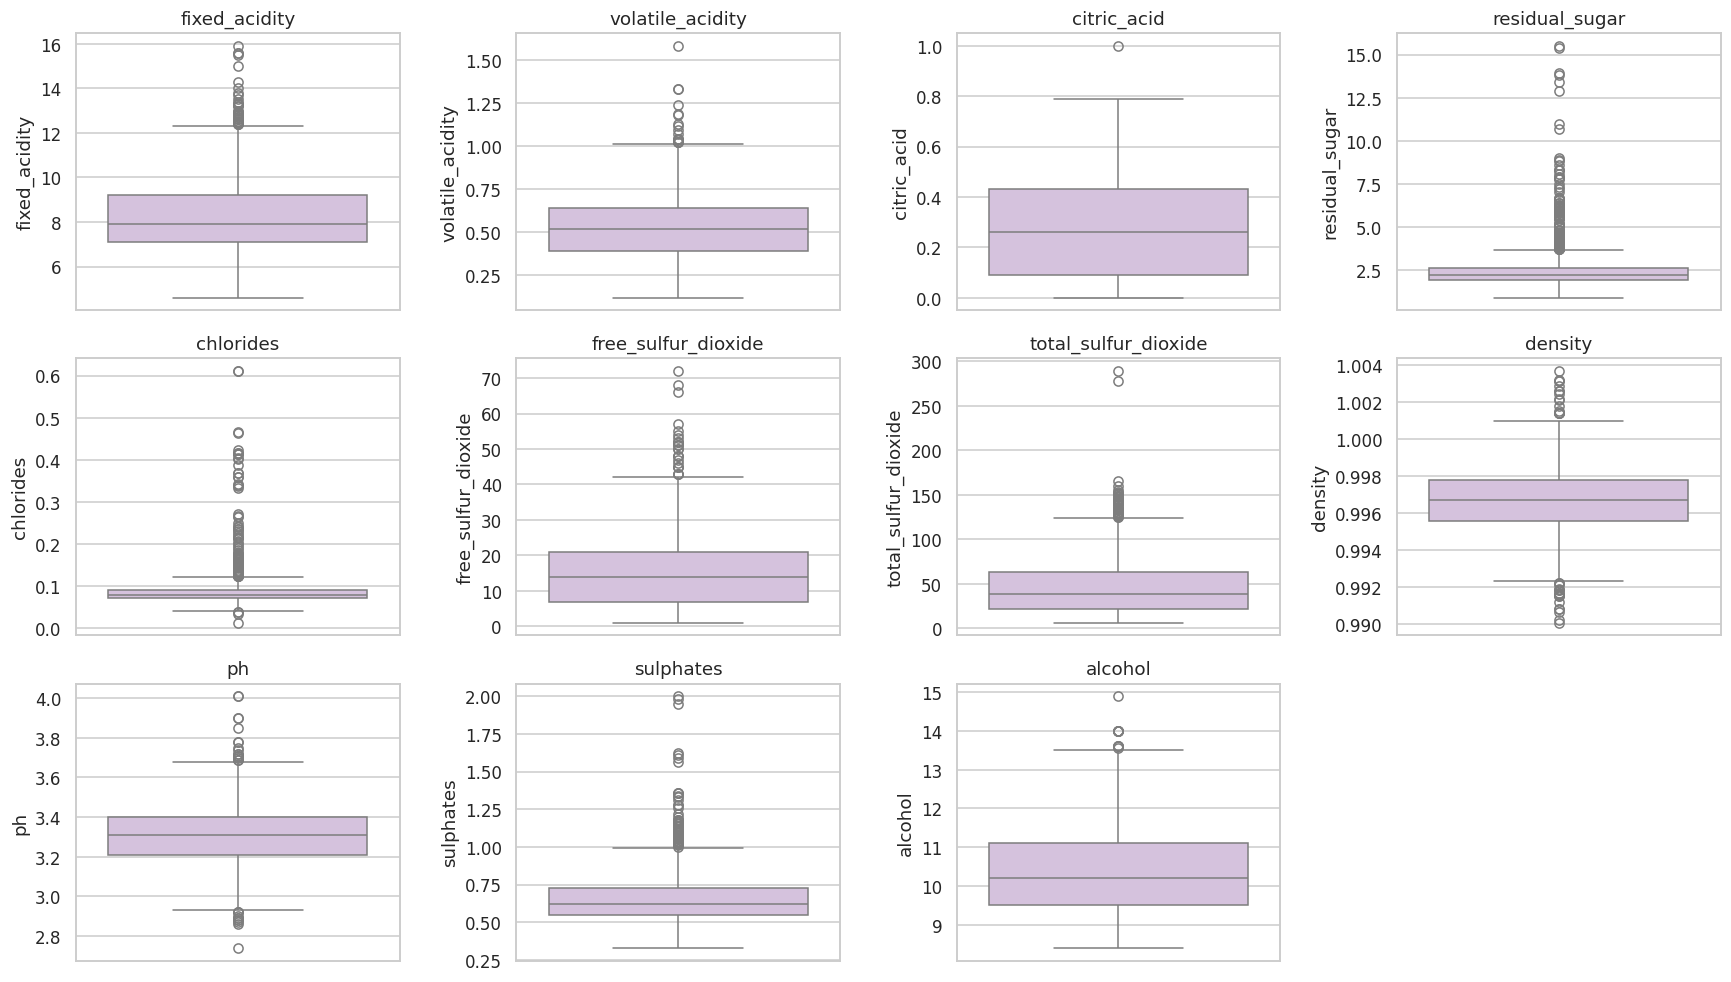

In [ ]:
# ---- 6. Outliers por IQR ----
def tabla_iqr(d, target="quality"):
    filas = []
    for c in d.columns.drop(target):
        q1, q3 = d[c].quantile([.25, .75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
        n = ((d[c] < lo) | (d[c] > hi)).sum()
        filas.append({"variable": c, "Q1": q1, "Q3": q3, "lim_inf": lo, "lim_sup": hi,
                      "n_outliers": n, "% outliers": 100*n/len(d)})
    return pd.DataFrame(filas).set_index("variable").sort_values("% outliers", ascending=False)

tab_out = tabla_iqr(df)
display(tab_out)

# Qué pasaría si eliminásemos toda fila con al menos un outlier
mask_any = pd.Series(False, index=df.index)
for c in df.columns.drop("quality"):
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    mask_any |= (df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)
print(f"\nFilas con al menos un outlier en alguna variable: {mask_any.sum()} ({mask_any.mean():.1%})")

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.ravel(), df.columns.drop("quality")):
    sns.boxplot(y=df[c], ax=ax, color="#d7bde2"); ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

**Decisión (punto 6): CONSERVAR los outliers.** Justificación:
1. **Son valores plausibles del dominio**, no errores de medición: hay vinos con mucho azúcar residual, cloruros o sulfatos altos de forma natural; no hay valores imposibles (pH fuera de 0–14, densidad absurda, negativos).
2. **Eliminarlos descartaría una fracción muy grande de datos** (ver porcentaje de filas con algún outlier) y justo los vinos "extremos" que más información aportan sobre calidad.
3. **El Árbol de Decisión es robusto a valores extremos** (parte por umbrales: un valor extremo sólo cae en una hoja). La Regresión Lineal es más sensible; por eso en la sección 7 (pregunta 21) se **verifica empíricamente** si quitar outliers del entrenamiento mejora algo.
4. Alternativa considerada: transformaciones (p. ej. `log1p` en `residual_sugar` y `chlorides`, muy asimétricas). No se aplica para mantener los coeficientes en las unidades originales y comparar en igualdad de condiciones; queda como posible mejora.

In [ ]:
# ---- 7. Unificación/estandarización de unidades y formatos ----
# Verificamos que las unidades sean coherentes y los valores plausibles
print("Tipos de dato:")
print(df.dtypes.value_counts())

checks = {
    "pH entre 0 y 14":                 df["ph"].between(0, 14).all(),
    "densidad entre 0.98 y 1.01 g/cm3": df["density"].between(0.98, 1.01).all(),
    "alcohol entre 5 y 20 %":          df["alcohol"].between(5, 20).all(),
    "SO2 libre <= SO2 total":          (df["free_sulfur_dioxide"] <= df["total_sulfur_dioxide"]).all(),
    "sin valores negativos":           (df.drop(columns=[]) >= 0).all().all(),
    "quality entero en [3, 8]":        df["quality"].between(3, 8).all() and (df["quality"] % 1 == 0).all(),
}
for k, v in checks.items():
    print(f"{'OK ' if v else 'REVISAR'} - {k}")

Tipos de dato:
float64    11
int64       1
Name: count, dtype: int64
OK  - pH entre 0 y 14
OK  - densidad entre 0.98 y 1.01 g/cm3
OK  - alcohol entre 5 y 20 %
OK  - SO2 libre <= SO2 total
OK  - sin valores negativos
OK  - quality entero en [3, 8]


**Decisión (punto 7):** las unidades ya son homogéneas dentro de cada variable (g/dm³, mg/dm³, % vol., etc.) y el formato es numérico en todas las columnas; las verificaciones de plausibilidad pasan. **No se requiere conversión de unidades.** El único "cambio de escala" necesario es la estandarización estadística para la regresión lineal (Etapa 3), que es una transformación para modelar y no una unificación de unidades.

In [ ]:
# ---- 8. Tamaño final tras la limpieza ----
print(f"Dataset original : {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
print(f"Duplicadas eliminadas: {n_dup}")
print(f"Nulos tratados: 0 | Outliers eliminados: 0 (se conservan)")
print(f"Dataset final    : {df.shape[0]} filas x {df.shape[1]} columnas")

Dataset original : 1599 filas x 12 columnas
Duplicadas eliminadas: 240
Nulos tratados: 0 | Outliers eliminados: 0 (se conservan)
Dataset final    : 1359 filas x 12 columnas


---
# ETAPA 3 — Transformación de datos

In [ ]:
# ---- 9. Separar X e y ----
X = df.drop(columns="quality")
y = df["quality"]
print("X:", X.shape, "| y:", y.shape)

# ---- 10. Partición 80/20 ----
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nDistribución de quality (proporción):")
print(pd.DataFrame({"train": y_train.value_counts(normalize=True).sort_index(),
                    "test":  y_test.value_counts(normalize=True).sort_index()}))

X: (1359, 11) | y: (1359,)
Train: (1087, 11) | Test: (272, 11)

Distribución de quality (proporción):
         train   test
quality              
3       0.0074 0.0074
4       0.0386 0.0404
5       0.4241 0.4265
6       0.3937 0.3934
7       0.1233 0.1213
8       0.0129 0.0110


**Decisión (punto 10):** partición 80/20 con `random_state=42` (reproducible) y **estratificada por `quality`**: como las clases 3 y 8 son muy raras, la estratificación asegura que ambas particiones tengan la misma distribución del target y una evaluación más estable.

In [ ]:
# ---- 11. Escalado ----
# Regresión Lineal: SÍ se escala (StandardScaler ajustado SOLO con train, para no filtrar info del test)
scaler = StandardScaler().fit(X_train)
X_train_sc = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_sc  = pd.DataFrame(scaler.transform(X_test),  columns=X.columns, index=X_test.index)

# Árbol de decisión: NO se escala (usa X_train / X_test originales)
X_train_sc.describe().loc[["mean", "std"]].round(3)

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol
mean,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000,-0.0000,0.0000,-0.0000
std,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


**Decisión (punto 11):**
- **Regresión Lineal → se escala** con `StandardScaler` (fit sólo en train). Las predicciones y métricas de OLS no cambian con el escalado, pero los coeficientes pasan a estar en "unidades de desvío estándar" y se vuelven **comparables entre variables** (con unidades originales, un coeficiente grande puede deberse sólo a que la variable tiene una escala pequeña, p. ej. `density`).
- **Árbol de Decisión → no se escala**: elige umbrales por variable y es invariante a transformaciones monótonas; el escalado no cambia las particiones ni las importancias.

---
# ETAPA 4 — Minería de datos

In [ ]:
# ---- 12. Regresión Lineal Múltiple (sobre datos escalados) ----
lin_reg = LinearRegression().fit(X_train_sc, y_train)
print("Intercepto:", round(lin_reg.intercept_, 4))
print("Modelo de regresión lineal entrenado.")

Intercepto: 5.6256
Modelo de regresión lineal entrenado.


In [ ]:
# ---- 13. Árboles de decisión de regresión: profundidades 3, 5 y sin límite ----
profundidades = [3, 5, None]
arboles = {}
for d in profundidades:
    arboles[d] = DecisionTreeRegressor(max_depth=d, random_state=SEED).fit(X_train, y_train)
    print(f"max_depth={d}: profundidad real={arboles[d].get_depth()}, hojas={arboles[d].get_n_leaves()}")

max_depth=3: profundidad real=3, hojas=8
max_depth=5: profundidad real=5, hojas=31
max_depth=None: profundidad real=20, hojas=313


Además de las tres profundidades pedidas, se explora un rango más amplio (1 a 20) para construir la curva de R² train/test y se elige la **profundidad óptima por validación cruzada de 5 folds sobre el conjunto de entrenamiento** —**no** mirando el conjunto de prueba—, de modo que el test siga siendo una evaluación honesta.

In [ ]:
# Selección de max_depth por validación cruzada (SOLO con train)
rango_prof = list(range(1, 21))
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_r2 = {}
for d in rango_prof:
    cv_r2[d] = cross_val_score(DecisionTreeRegressor(max_depth=d, random_state=SEED),
                               X_train, y_train, cv=kf, scoring="r2").mean()

mejor_prof = max(cv_r2, key=cv_r2.get)
print(pd.Series(cv_r2, name="R2 medio CV (5 folds)").to_frame().T.round(3).to_string())
print(f"\n>>> Mejor profundidad según CV: {mejor_prof}  (R2 CV = {cv_r2[mejor_prof]:.4f})")

arbol_mejor = DecisionTreeRegressor(max_depth=mejor_prof, random_state=SEED).fit(X_train, y_train)

                          1      2      3      4      5      6      7      8      9       10      11      12      13      14      15      16      17      18      19      20
R2 medio CV (5 folds) 0.1580 0.2160 0.2900 0.2850 0.2440 0.2380 0.2070 0.1070 0.0360 -0.0150 -0.0440 -0.0850 -0.0900 -0.1090 -0.1030 -0.1070 -0.1310 -0.1380 -0.1540 -0.1460

>>> Mejor profundidad según CV: 3  (R2 CV = 0.2902)


---
# ETAPA 5 — Interpretación y evaluación de resultados

In [ ]:
# ---- 14. Regresión Lineal: métricas en test (y train como referencia) ----
res_lr = pd.DataFrame({
    "train": metricas(y_train, lin_reg.predict(X_train_sc)),
    "test":  metricas(y_test,  lin_reg.predict(X_test_sc)),
}).T
print("REGRESIÓN LINEAL")
display(res_lr)

REGRESIÓN LINEAL


,MAE,RMSE,R2
train,0.5100,0.6595,0.3599
test,0.5066,0.6523,0.3657


In [ ]:
# ---- 15. Árbol: MAE, RMSE y R2 en train y test para cada profundidad ----
filas = []
for d, modelo in arboles.items():
    mtr = metricas(y_train, modelo.predict(X_train))
    mte = metricas(y_test,  modelo.predict(X_test))
    filas.append({
        "max_depth": "sin límite" if d is None else d,
        "MAE_train": mtr["MAE"], "MAE_test": mte["MAE"],
        "RMSE_train": mtr["RMSE"], "RMSE_test": mte["RMSE"],
        "R2_train": mtr["R2"], "R2_test": mte["R2"],
        "Brecha R2 (train-test)": mtr["R2"] - mte["R2"],
    })
res_arbol = pd.DataFrame(filas).set_index("max_depth")
display(res_arbol)

,MAE_train,MAE_test,RMSE_train,RMSE_test,R2_train,R2_test,Brecha R2 (train-test)
max_depth,,,,,,,
3,0.5215,0.5685,0.6614,0.7017,0.3561,0.2661,0.0901
5,0.4501,0.5451,0.5850,0.7032,0.4963,0.2629,0.2334
sin límite,0.0000,0.5919,0.0000,0.8849,1.0000,-0.1673,1.1673


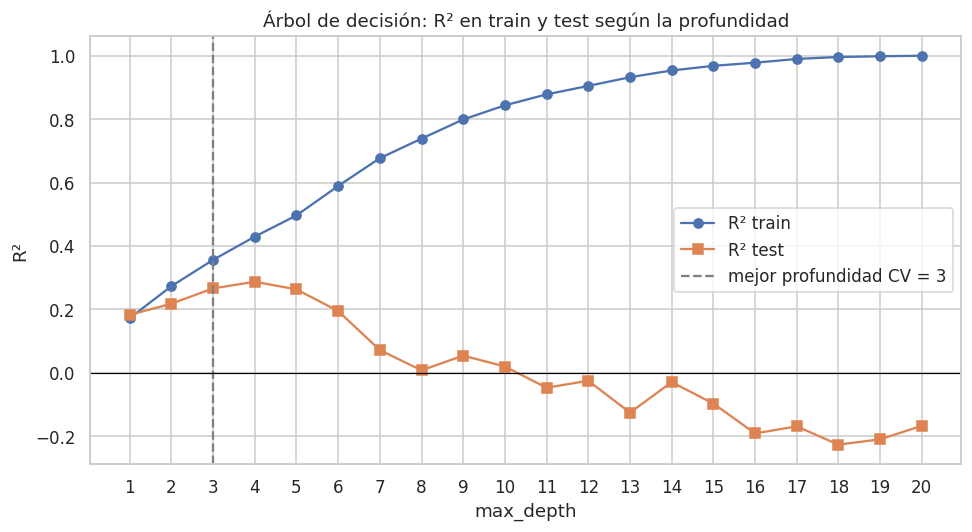

Profundidad con mayor R² de test (descriptivo): 4
Profundidad elegida por CV (usada como modelo final): 3


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
R2_train,0.1720,0.2730,0.3560,0.4290,0.4960,0.5890,0.6770,0.7380,0.7990,0.8440,0.8780,0.9050,0.9320,0.9530,0.9680,0.9780,0.9900,0.9960,0.9980,1.0000
R2_test,0.1830,0.2180,0.2660,0.2870,0.2630,0.1950,0.0720,0.0080,0.0540,0.0200,-0.0470,-0.0250,-0.1260,-0.0290,-0.0970,-0.1910,-0.1690,-0.2270,-0.2100,-0.1670
brecha,-0.0100,0.0550,0.0900,0.1420,0.2330,0.3940,0.6050,0.7310,0.7450,0.8240,0.9250,0.9300,1.0580,0.9830,1.0650,1.1690,1.1590,1.2230,1.2080,1.1670


In [ ]:
# Curva de R2 train/test según la profundidad (gráfico requerido)
r2_tr, r2_te = [], []
for d in rango_prof:
    m = DecisionTreeRegressor(max_depth=d, random_state=SEED).fit(X_train, y_train)
    r2_tr.append(r2_score(y_train, m.predict(X_train)))
    r2_te.append(r2_score(y_test,  m.predict(X_test)))

plt.figure(figsize=(9, 5))
plt.plot(rango_prof, r2_tr, "o-", label="R² train")
plt.plot(rango_prof, r2_te, "s-", label="R² test")
plt.axvline(mejor_prof, ls="--", color="gray", label=f"mejor profundidad CV = {mejor_prof}")
plt.axhline(0, color="black", lw=0.8)
plt.xlabel("max_depth"); plt.ylabel("R²"); plt.xticks(rango_prof)
plt.title("Árbol de decisión: R² en train y test según la profundidad")
plt.legend(); plt.tight_layout(); plt.show()

curva = pd.DataFrame({"R2_train": r2_tr, "R2_test": r2_te}, index=rango_prof)
curva["brecha"] = curva["R2_train"] - curva["R2_test"]
prof_max_test = curva["R2_test"].idxmax()
print(f"Profundidad con mayor R² de test (descriptivo): {prof_max_test}")
print(f"Profundidad elegida por CV (usada como modelo final): {mejor_prof}")
curva.round(3).T

**Análisis de sobreajuste (punto 15)**
- Con profundidades bajas (1–3) el árbol es simple: R² de train y de test son parecidos y bajos → **subajuste** (sesgo alto).
- A medida que `max_depth` crece, el R² de **train sube sin parar** (hasta ≈ 1 sin límite) mientras que el R² de **test deja de mejorar y luego cae**: la **brecha se ensancha**. Ese punto de quiebre (alrededor del valor de profundidad donde el R² de test alcanza su máximo y empieza a descender) marca el inicio del **sobreajuste**: el árbol empieza a memorizar ruido de entrenamiento.
- Sin límite de profundidad, el árbol llega a una hoja por observación (R² train ≈ 1) y el R² de test queda muy por debajo del de los árboles podados: **sobreajuste extremo**.

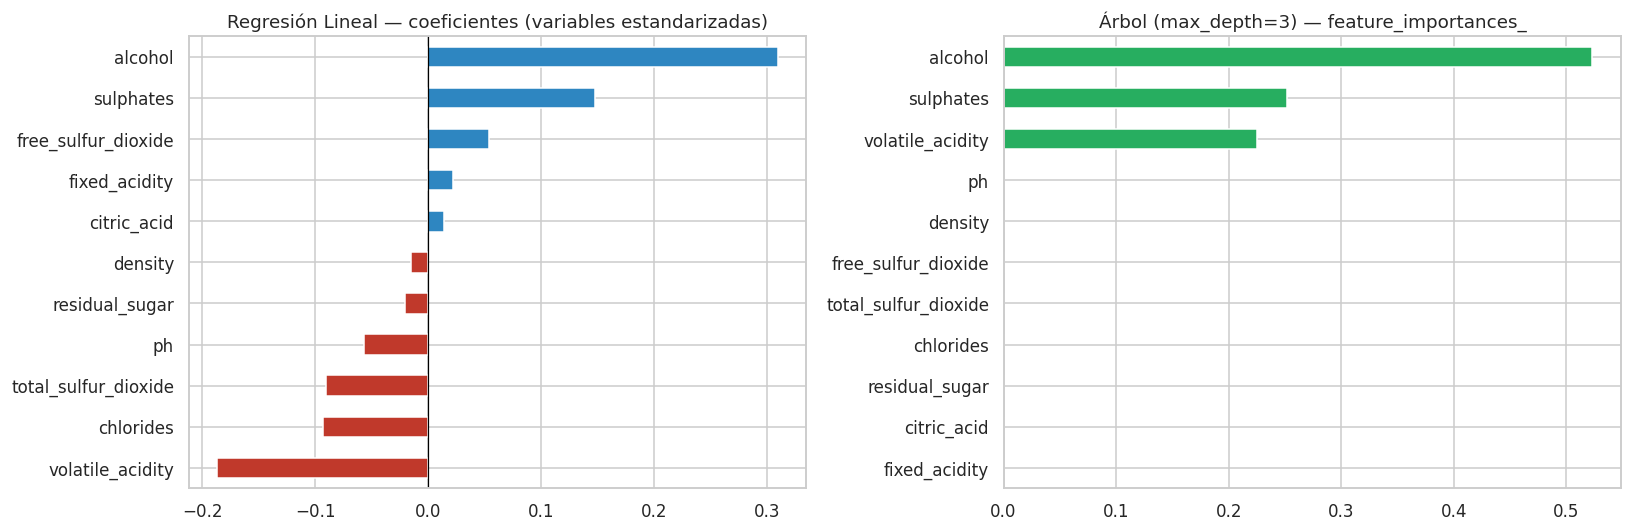

Top coeficientes por magnitud (LR):
alcohol                 0.3101
volatile_acidity       -0.1875
sulphates               0.1478
chlorides              -0.0929
total_sulfur_dioxide   -0.0904
ph                     -0.0565
dtype: float64

Top importancias (árbol):
alcohol            0.5228
sulphates          0.2518
volatile_acidity   0.2255
residual_sugar     0.0000
citric_acid        0.0000
fixed_acidity      0.0000
dtype: float64


In [ ]:
# ---- 16. Interpretación: coeficientes (LR) e importancias (árbol) ----
coef = pd.Series(lin_reg.coef_, index=X.columns).sort_values()
imp  = pd.Series(arbol_mejor.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
coef.plot.barh(ax=ax[0], color=["#c0392b" if v < 0 else "#2e86c1" for v in coef])
ax[0].set_title("Regresión Lineal — coeficientes (variables estandarizadas)")
ax[0].axvline(0, color="black", lw=0.8)
imp.plot.barh(ax=ax[1], color="#27ae60")
ax[1].set_title(f"Árbol (max_depth={mejor_prof}) — feature_importances_")
plt.tight_layout(); plt.show()

print("Top coeficientes por magnitud (LR):")
print(coef.reindex(coef.abs().sort_values(ascending=False).index).round(4).head(6))
print("\nTop importancias (árbol):")
print(imp.sort_values(ascending=False).round(4).head(6))

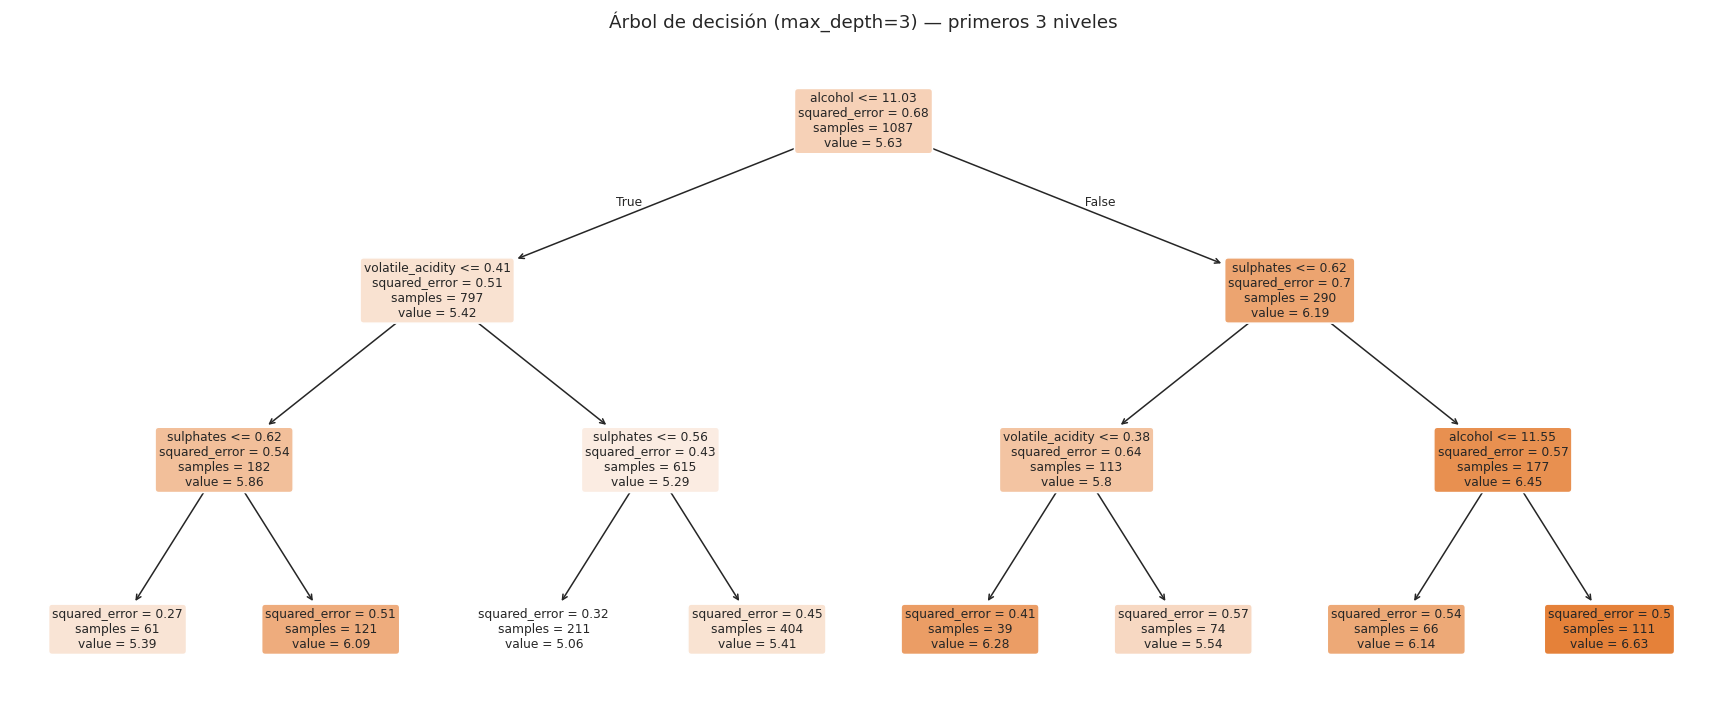

In [ ]:
# Vista del árbol elegido (se muestran los primeros niveles para que sea legible)
plt.figure(figsize=(20, 8))
plot_tree(arbol_mejor, feature_names=list(X.columns), filled=True, rounded=True,
          max_depth=3, fontsize=8, precision=2)
plt.title(f"Árbol de decisión (max_depth={mejor_prof}) — primeros 3 niveles")
plt.show()

**Interpretación (punto 16):** completar con los valores de las salidas anteriores. Lo esperable en este dataset es que:
- **Regresión Lineal:** `alcohol` (coeficiente positivo) y `volatile_acidity` (negativo) sean los de mayor magnitud, seguidas de `sulphates` (positivo) y `total_sulfur_dioxide` (negativo). Hay que interpretar con cautela los coeficientes de las variables correlacionadas entre sí (`fixed_acidity`, `density`, `citric_acid`, `ph`) por la **multicolinealidad**: sus signos y magnitudes pueden ser inestables.
- **Árbol:** `alcohol`, `sulphates` y `volatile_acidity` concentran la mayor parte de la importancia, ya que son las que producen las primeras particiones.
- Que ambos modelos coincidan en las variables clave refuerza la conclusión de que son los principales predictores fisicoquímicos de la calidad. Las importancias del árbol no indican el *signo* del efecto (el coeficiente lineal sí).

---
# ETAPA 6 — Selección del modelo final y conclusiones

In [ ]:
# ---- 17. Tabla comparativa final (conjunto de prueba) ----
fila_lr = metricas(y_test, lin_reg.predict(X_test_sc))
fila_ar = metricas(y_test, arbol_mejor.predict(X_test))
fila_ar_full = metricas(y_test, arboles[None].predict(X_test))

tabla_final = pd.DataFrame({
    "Regresión Lineal": fila_lr,
    f"Árbol (max_depth={mejor_prof}, elegido por CV)": fila_ar,
    "Árbol sin límite (referencia)": fila_ar_full,
}).T
display(tabla_final)

# Robustez: validación cruzada 5 folds sobre TRAIN (pipelines sin fuga de información)
cv_lr = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()),
                        X_train, y_train, cv=kf, scoring="r2")
cv_ar = cross_val_score(DecisionTreeRegressor(max_depth=mejor_prof, random_state=SEED),
                        X_train, y_train, cv=kf, scoring="r2")
robustez = pd.DataFrame({
    "R2 CV media": [cv_lr.mean(), cv_ar.mean()],
    "R2 CV desvío": [cv_lr.std(), cv_ar.std()],
    "Brecha R2 train-test": [
        res_lr.loc["train", "R2"] - res_lr.loc["test", "R2"],
        r2_score(y_train, arbol_mejor.predict(X_train)) - fila_ar["R2"]],
}, index=["Regresión Lineal", f"Árbol (depth={mejor_prof})"])
print("\nRobustez / estabilidad:")
display(robustez)

,MAE,RMSE,R2
Regresión Lineal,0.5066,0.6523,0.3657
"Árbol (max_depth=3, elegido por CV)",0.5685,0.7017,0.2661
Árbol sin límite (referencia),0.5919,0.8849,-0.1673



Robustez / estabilidad:


,R2 CV media,R2 CV desvío,Brecha R2 train-test
Regresión Lineal,0.3410,0.0279,-0.0058
Árbol (depth=3),0.2902,0.0557,0.0901


Mejor RMSE en test : Regresión Lineal
Mejor R2 en test   : Regresión Lineal


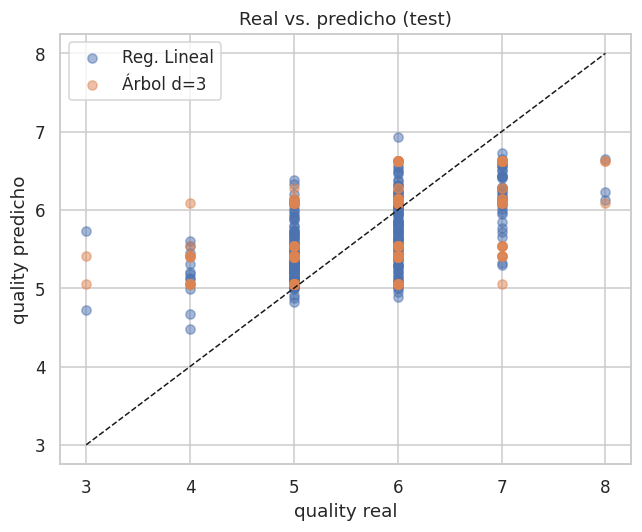

In [ ]:
# ---- 18. Selección del modelo final ----
ganador_rmse = tabla_final.iloc[:2]["RMSE"].idxmin()
ganador_r2   = tabla_final.iloc[:2]["R2"].idxmax()
print("Mejor RMSE en test :", ganador_rmse)
print("Mejor R2 en test   :", ganador_r2)

plt.figure(figsize=(6, 5))
plt.scatter(y_test, lin_reg.predict(X_test_sc), alpha=0.5, label="Reg. Lineal")
plt.scatter(y_test, arbol_mejor.predict(X_test), alpha=0.5, label=f"Árbol d={mejor_prof}")
plt.plot([3, 8], [3, 8], "k--", lw=1)
plt.xlabel("quality real"); plt.ylabel("quality predicho"); plt.legend()
plt.title("Real vs. predicho (test)"); plt.tight_layout(); plt.show()

**Criterios para la selección final (punto 18):**
| Criterio | Regresión Lineal | Árbol (podado) |
|---|---|---|
| Métricas (MAE/RMSE/R²) en test | ver tabla | ver tabla |
| Interpretabilidad | Alta: coeficiente = efecto marginal y signo de cada variable | Alta en reglas, pero con un árbol profundo se vuelve difícil de leer |
| Robustez / estabilidad | Estable (baja varianza), sensible a outliers y multicolinealidad | Alta varianza: cambia mucho con pequeñas variaciones de los datos; muy sensible a `max_depth` |
| Relaciones no lineales / interacciones | No las captura | Sí las captura |
| Sobreajuste | Bajo (brecha train-test pequeña) | Riesgo alto si la profundidad no está controlada |

**Cómo decidir:** se elige el modelo con mejor desempeño en test (RMSE/R²) **y** estabilidad en CV. Si las métricas son similares, se prefiere la **Regresión Lineal** por ser más simple, estable e interpretable (principio de parsimonia). Sólo se elegiría el árbol si su ventaja en test es clara y consistente en la validación cruzada. **Escribir aquí la decisión final con los números obtenidos en la corrida.**

### Conclusión (punto 19)
*(Redactar/ajustar con los números de la tabla final; el esquema esperable es:)*

- Con **sólo variables fisicoquímicas** se logra una capacidad predictiva **moderada**: el R² en test de ambos modelos suele ubicarse alrededor de 0,3–0,4 y el MAE en torno a 0,5 puntos de calidad. Es decir, las variables de laboratorio explican una parte —no la totalidad— de la variabilidad del puntaje.
- La calidad sensorial depende también de factores **no medidos** (variedad de uva, añada, terroir, aromas/compuestos volátiles, envejecimiento) y de la **subjetividad del panel de cata**; además `quality` es una escala discreta y concentrada en 5 y 6, lo que dificulta predecir los extremos.
- Las variables más relevantes (`alcohol`, `volatile_acidity`, `sulphates`) coinciden en ambos modelos, lo que da consistencia al hallazgo.
- **Posibles mejoras:** (1) transformar variables asimétricas (`log1p`), (2) agregar interacciones/términos polinómicos, (3) modelos de ensamble (Random Forest, Gradient Boosting) que reducen la varianza del árbol, (4) regularización (Ridge/Lasso) por la multicolinealidad, (5) plantear el problema como clasificación (calidad baja/media/alta), (6) validación cruzada repetida para una estimación más estable, (7) incorporar más variables (uva, añada, zona) y más datos en los extremos de la escala.

---
# SECCIÓN 5 — Preguntas de análisis

### Pregunta 20 — ¿Por qué eliminar duplicados exactos *antes* de dividir en train/test?
Porque si una misma observación aparece repetida y se hace el split después, **una copia puede quedar en entrenamiento y la otra en prueba**. El modelo "ya vio" ese dato, por lo que acierta sobre él sin haber generalizado: es una forma de **fuga de datos (*data leakage*)**. Consecuencias: (a) el conjunto de prueba deja de ser independiente y las métricas resultan **optimistas**; (b) se **favorece artificialmente a modelos que memorizan** (árbol profundo, k-NN) frente a los que generalizan; (c) las filas repetidas pesan más en el ajuste. Al deduplicar antes del split se garantiza que el test contenga únicamente casos que el modelo nunca vio y la evaluación refleje su desempeño real. *(Matiz: en este dataset puede haber vinos distintos con idénticas mediciones por la baja resolución de los instrumentos; aun así, la práctica conservadora es eliminarlos para evitar la fuga.)*

In [ ]:
# Evidencia empírica de la fuga: cuántas filas de test tienen un duplicado exacto en train
# usando el dataset CON duplicados (df_con_dup) y el mismo tipo de split
Xd, yd = df_con_dup.drop(columns="quality"), df_con_dup["quality"]
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.2, random_state=SEED, stratify=yd)
m = Xd_te.merge(Xd_tr.drop_duplicates(), how="left", on=list(Xd.columns), indicator=True)
pct = (m["_merge"] == "both").mean()
print(f"Con duplicados: {pct:.1%} de las filas de TEST tienen una copia exacta en TRAIN")

m2 = X_test.merge(X_train.drop_duplicates(), how="left", on=list(X.columns), indicator=True)
print(f"Sin duplicados: {(m2['_merge'] == 'both').mean():.1%} de las filas de TEST tienen una copia exacta en TRAIN")

Con duplicados: 23.8% de las filas de TEST tienen una copia exacta en TRAIN
Sin duplicados: 0.0% de las filas de TEST tienen una copia exacta en TRAIN


### Pregunta 21 — ¿Eliminar o conservar los outliers detectados por IQR?
**Se conservan.** (1) Con IQR algunas variables superan el 9 % de "atípicos": eliminarlos significaría **perder muchísimas filas** (ver el porcentaje de filas con algún outlier) y reducir el tamaño muestral. (2) Son **valores plausibles del dominio** (vinos naturalmente más ricos en azúcar, cloruros o sulfatos), no errores; además, muchos corresponden a vinos de calidad extrema, justo los más difíciles de predecir y más informativos. (3) El **árbol es robusto** a extremos (los aísla en hojas con umbrales); la **regresión lineal es más sensible**, por lo que se verifica a continuación empíricamente si recortarlos en entrenamiento aporta algo. (4) Si el efecto fuese negativo, una alternativa más suave que eliminar es **transformar** (log) o usar modelos robustos (Huber).

In [ ]:
# Experimento: quitar outliers (IQR) SOLO del train y evaluar sobre el MISMO test
mask = pd.Series(True, index=X_train.index)
for c in X_train.columns:
    q1, q3 = X_train[c].quantile([.25, .75]); iqr = q3 - q1
    mask &= X_train[c].between(q1 - 1.5*iqr, q3 + 1.5*iqr)

Xtr_f, ytr_f = X_train[mask], y_train[mask]
print(f"Train original: {len(X_train)} filas | sin outliers: {len(Xtr_f)} filas "
      f"({1 - len(Xtr_f)/len(X_train):.1%} descartadas)")

sc_f = StandardScaler().fit(Xtr_f)
lr_f = LinearRegression().fit(sc_f.transform(Xtr_f), ytr_f)
ar_f = DecisionTreeRegressor(max_depth=mejor_prof, random_state=SEED).fit(Xtr_f, ytr_f)

comp_out = pd.DataFrame({
    "LR - conservando outliers":  metricas(y_test, lin_reg.predict(X_test_sc)),
    "LR - sin outliers (train)":  metricas(y_test, lr_f.predict(sc_f.transform(X_test))),
    "Árbol - conservando":        metricas(y_test, arbol_mejor.predict(X_test)),
    "Árbol - sin outliers (train)": metricas(y_test, ar_f.predict(X_test)),
}).T
display(comp_out)

Train original: 1087 filas | sin outliers: 813 filas (25.2% descartadas)


,MAE,RMSE,R2
LR - conservando outliers,0.5066,0.6523,0.3657
LR - sin outliers (train),0.5371,0.7056,0.2578
Árbol - conservando,0.5685,0.7017,0.2661
Árbol - sin outliers (train),0.5457,0.6797,0.3114


Si las métricas no mejoran de forma clara al quitar outliers (lo habitual aquí), queda respaldada la decisión de **conservarlos**.

### Pregunta 22 — ¿Por qué escalar para interpretar los coeficientes de la Regresión Lineal pero no para el árbol?
- **Regresión Lineal:** el coeficiente de una variable es el cambio en `quality` por **cada unidad** de esa variable. Si las unidades/escalas son distintas (g/dm³, mg/dm³, 0–14…), los coeficientes **no son comparables**: `density` (rango ~0,01) tendrá un coeficiente enorme y `total_sulfur_dioxide` (rango ~280) uno diminuto sin que eso diga cuál importa más. Con `StandardScaler`, cada coeficiente pasa a ser el cambio en `quality` por **1 desvío estándar**, y las magnitudes se pueden comparar. El escalado **no cambia las predicciones ni las métricas** de OLS, sólo la interpretación.
- **Árbol:** cada nodo busca un umbral sobre una variable a la vez; ese umbral se acomoda a la escala de la variable, y las particiones resultantes son las mismas con o sin escalado (invarianza ante transformaciones monótonas). Por eso las importancias y las predicciones no cambian.

In [ ]:
# Demostración empírica
lr_orig = LinearRegression().fit(X_train, y_train)                 # sin escalar
comp_coef = pd.DataFrame({"coef sin escalar": lr_orig.coef_, "coef estandarizado": lin_reg.coef_}, index=X.columns)
display(comp_coef)
print("¿Mismas predicciones en test con y sin escalar? ->",
      np.allclose(lr_orig.predict(X_test), lin_reg.predict(X_test_sc)))

arbol_sc = DecisionTreeRegressor(max_depth=mejor_prof, random_state=SEED).fit(X_train_sc, y_train)
print("¿Mismas predicciones del árbol con y sin escalar? ->",
      np.allclose(arbol_sc.predict(X_test_sc), arbol_mejor.predict(X_test)))
print("¿Mismas importancias? ->", np.allclose(arbol_sc.feature_importances_, arbol_mejor.feature_importances_))

,coef sin escalar,coef estandarizado
fixed_acidity,0.0122,0.0218
volatile_acidity,-1.0099,-0.1875
citric_acid,0.0731,0.0144
residual_sugar,-0.0154,-0.0207
chlorides,-1.9506,-0.0929
free_sulfur_dioxide,0.0050,0.0535
total_sulfur_dioxide,-0.0026,-0.0904
density,-7.9223,-0.0152
ph,-0.3557,-0.0565
sulphates,0.8720,0.1478


¿Mismas predicciones en test con y sin escalar? -> True
¿Mismas predicciones del árbol con y sin escalar? -> True
¿Mismas importancias? -> True


### Pregunta 23 — ¿Qué significa un R² negativo y qué revela un R² train ≈ 1 con test negativo?
$R^2 = 1 - \dfrac{SS_{res}}{SS_{tot}}$ compara el error del modelo con el de un **modelo trivial que siempre predice la media**. Un **R² negativo** indica que el modelo predice **peor que simplemente usar la media** (SS_res > SS_tot). Un árbol sin límite de profundidad crece hasta tener (casi) una hoja por observación, **memoriza** el entrenamiento y logra R² train ≈ 1 (error ≈ 0). Si en test el R² es negativo (o muy bajo) hay una brecha enorme: el árbol aprendió ruido y casos particulares en lugar de la relación general, y sus predicciones sobre datos nuevos son peores que una constante. Es la señal de **sobreajuste extremo** (varianza muy alta). Se controla limitando `max_depth`, `min_samples_leaf`, podando (`ccp_alpha`) o usando ensambles.

In [ ]:
d_full = res_arbol.loc["sin límite"]
print(f"Árbol sin límite -> R2 train = {d_full['R2_train']:.3f} | R2 test = {d_full['R2_test']:.3f} | brecha = {d_full['Brecha R2 (train-test)']:.3f}")

Árbol sin límite -> R2 train = 1.000 | R2 test = -0.167 | brecha = 1.167


### Pregunta 24 — Repetir la comparación final sin haber eliminado los duplicados
Se repite **todo el pipeline** (split estratificado, escalado sólo para LR, elección de profundidad por CV, evaluación en test) con el dataset **con** duplicados y se compara contra el limpio.

In [ ]:
def correr_experimento(d, etiqueta, seed=SEED):
    Xe, ye = d.drop(columns="quality"), d["quality"]
    Xtr, Xte, ytr, yte = train_test_split(Xe, ye, test_size=0.2, random_state=seed, stratify=ye)
    sc = StandardScaler().fit(Xtr)
    lr = LinearRegression().fit(sc.transform(Xtr), ytr)

    kf_ = KFold(5, shuffle=True, random_state=seed)
    cv_ = {k: cross_val_score(DecisionTreeRegressor(max_depth=k, random_state=seed), Xtr, ytr, cv=kf_, scoring="r2").mean()
           for k in range(1, 21)}
    kbest = max(cv_, key=cv_.get)
    ar = DecisionTreeRegressor(max_depth=kbest, random_state=seed).fit(Xtr, ytr)
    ar_full = DecisionTreeRegressor(random_state=seed).fit(Xtr, ytr)

    out = pd.DataFrame({
        "Regresión Lineal": metricas(yte, lr.predict(sc.transform(Xte))),
        f"Árbol (depth={kbest} por CV)": metricas(yte, ar.predict(Xte)),
        "Árbol sin límite": metricas(yte, ar_full.predict(Xte)),
    }).T
    out.insert(0, "dataset", etiqueta)
    out.insert(1, "n_filas", len(d))
    return out

comparacion = pd.concat([
    correr_experimento(df, "SIN duplicados (limpio)"),
    correr_experimento(df_con_dup, "CON duplicados"),
])
display(comparacion)

,dataset,n_filas,MAE,RMSE,R2
Regresión Lineal,SIN duplicados (limpio),1359,0.5066,0.6523,0.3657
Árbol (depth=3 por CV),SIN duplicados (limpio),1359,0.5685,0.7017,0.2661
Árbol sin límite,SIN duplicados (limpio),1359,0.5919,0.8849,-0.1673
Regresión Lineal,CON duplicados,1599,0.4951,0.6375,0.3703
Árbol (depth=5 por CV),CON duplicados,1599,0.5285,0.7039,0.2320
Árbol sin límite,CON duplicados,1599,0.4125,0.7500,0.1283


**Análisis (a completar con la tabla anterior):**
- Con duplicados **mejoran las métricas de test, especialmente las de los modelos que memorizan** (el árbol profundo y/o sin límite), porque parte del test ya está en el entrenamiento (fuga). La Regresión Lineal casi no cambia, ya que no puede memorizar observaciones.
- Esa ventaja es **artificial**: puede **achicar la distancia entre árbol y regresión lineal o incluso invertir el ranking**, llevando a elegir un modelo "mejor" que en producción no lo es. Con datos limpios, el árbol sin límite colapsa en test y la regresión lineal (o un árbol podado) queda mejor posicionada.
- **Moraleja KDD:** las etapas tempranas (limpieza) condicionan todo lo posterior: una decisión de preprocesamiento puede cambiar el modelo seleccionado y la confianza en las métricas reportadas. Por eso se documenta y justifica cada decisión, y se hace la limpieza **antes** de particionar. Como el split es aleatorio, conviene además repetirlo con distintas semillas o usar CV repetida para saber si las diferencias son reales o ruido.